In [300]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import least_squares
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
import math

In [301]:
df = pd.read_excel("df2.xlsx", header=1)[["Время T", 8]]
df.columns = ['t', 'population']
df.head()

,t,population
0,5.0,66
1,5.1,73
2,5.2,66
3,5.3,68
4,5.4,81


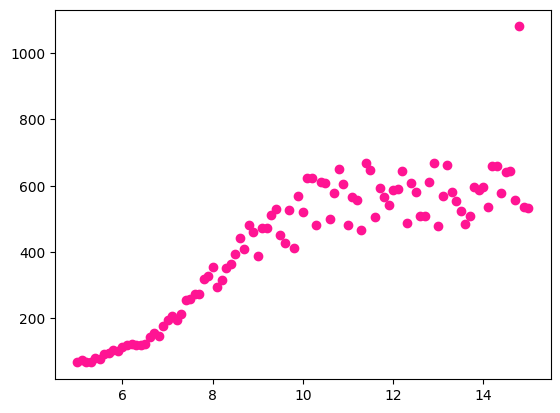

In [302]:
plt.scatter(x=df["t"], y=df["population"], color='deeppink')
plt.show()

### Изучив данное нам распределение и поведение функции, смело можно сделать вывод, что это некоторая логистическая функция (также значение роста популяции часто описывается именно этой функцией). Логистическая функция имеет вид
## P(t) = e^t/(1 + e^t)
### и принадлежит от 0 до 1. Мы видим, что наше распределение при этом имеет другой промежуток значений, для того чтобы увеличить, будет достаточным умножить функцию на некоторый параметр c. Предположительно он около 600-700, это видно по графику. Такой параметр (из-за большого значения) может создать риск переобучения, но пока оставим так.
### Также заметим, что классическая логистическая функция не слишком описывает поведение нашей зависимости, но это можно изменить, добавив линейную зависимость в степени e (это становится ясно при изучении функции в десмосе)
### попробуем также добавить свободную константу d, изначально равную нулю (сдвиг по оси y вверх или вниз)

### Тогда, целевая функция принимает вид
## ce^(ax + b)/(1 + e^(ax + b)) + d

# Задание 1

[  1.02166953  -8.14221838 555.89865235  38.78226407]


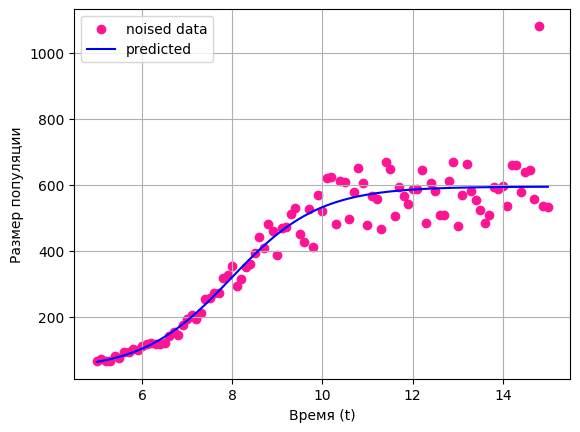

In [303]:
x = df.t
y = df.population

def g(x,t,y):
  e = math.e
  a = x[0]
  b = x[1]
  c = x[2]
  d = x[3]
  return c * e**(a * t + b)/(1 + e**(a * t + b)) + x[3] - y

inits = [1, 1, 1, 0] # начальные веса
lsm = least_squares(g,inits,args=(x,y))
print(lsm.x)
ypred_box = g(lsm.x,x,0)

plt.scatter(x,y,label='noised data', color="deeppink")
plt.plot(x,ypred_box, color='blue',label='predicted')
plt.xlabel('Время (t)')
plt.ylabel('Размер популяции')
plt.legend()
plt.grid(True)
plt.show()

# Задание 2

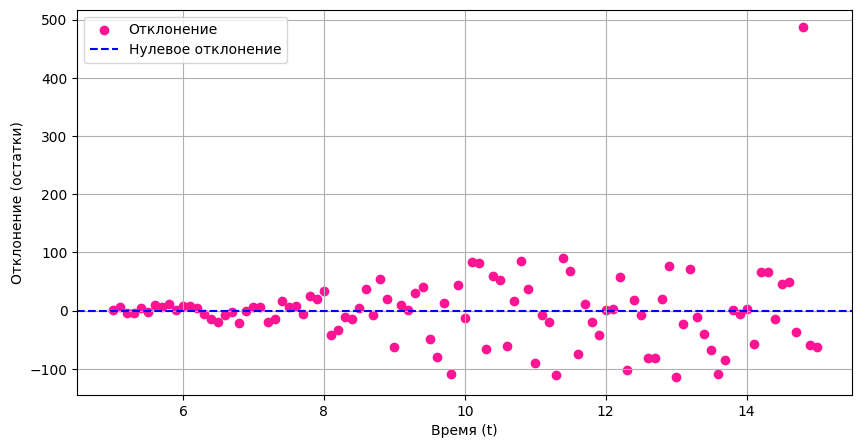

In [304]:
residuals = y - ypred_box

plt.figure(figsize=(10, 5))
plt.scatter(x, residuals, color='deeppink', label='Отклонение')
plt.axhline(y=0, linestyle='--', color='blue', label='Нулевое отклонение')
plt.xlabel('Время (t)')
plt.ylabel('Отклонение (остатки)')
plt.legend()
plt.grid(True)
plt.show()

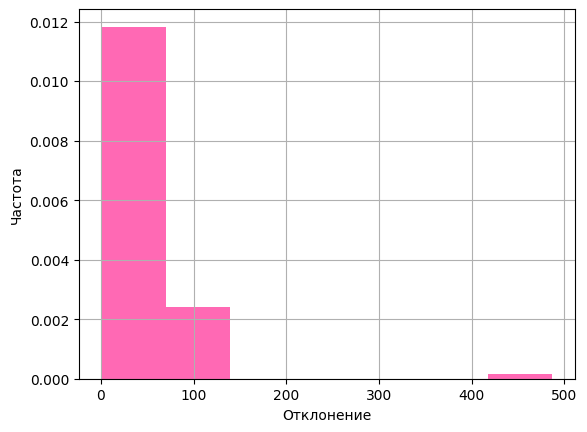

In [305]:
# посмотрим на частоту отклонений
residuals = np.abs(y - ypred_box)

ymin, ymax = np.min(residuals), np.max(residuals)
n = y.shape[0]
N = int(1 + 3.2 * np.log10(n))
R = ymax - ymin
step = R / N
plt.ylabel('Частота')
plt.xlabel('Отклонение')
plt.hist(residuals, N, color='hotpink', density=True)
plt.grid()
plt.show()

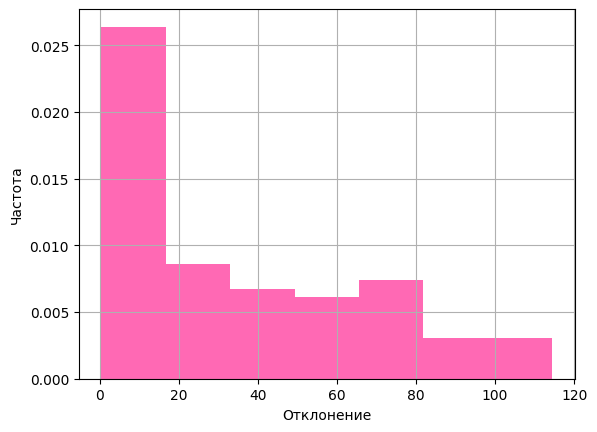

In [306]:
# посмотрим поближе без выброса
clean_y = y[y < np.max(y)]
residuals = np.abs(clean_y - ypred_box)

ymin, ymax = np.min(residuals), np.max(residuals)
n = y.shape[0]
N = int(1 + 3.2 * np.log10(n))
R = ymax - ymin
step = R / N
plt.ylabel('Частота')
plt.xlabel('Отклонение')
plt.hist(residuals, N, color='hotpink', density=True)
plt.grid()
plt.show()

In [307]:
residuals = y - ypred_box
print("MAE:", np.mean(np.abs(residuals)))

MAE: 39.36661024472318


In [308]:
print("Популяция на старте, T=0:", g(lsm.x, 0, 0))

Популяция на старте, T=0: 38.943978494486785


# Задание 3

### В нашей функции есть единственное значение, сильно отличающееся от некоторой существующей зависимости, оно не стремится к "устойчивому состоянию". Попробуем убрать его и посмотрим на результат.

[  1.13577446  -9.03904812 527.70205308  52.10878955]


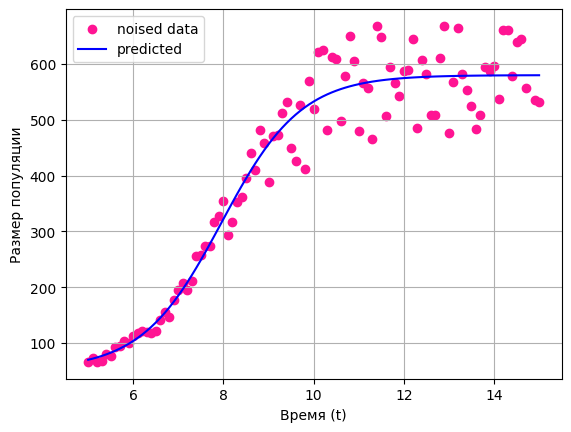

In [309]:
clean_df = df[df.population < np.max(df.population)]
x = clean_df.t
y = clean_df.population

def g(x,t,y):
  e = math.e
  a = x[0]
  b = x[1]
  c = x[2]
  d = x[3]
  return c * e**(a * t + b)/(1 + e**(a * t + b)) + x[3] - y

inits = [1, 1, 1, 0] # начальные веса
lsm = least_squares(g,inits,args=(x,y))
print(lsm.x)
ypred_box = g(lsm.x,x,0)

plt.scatter(x,y,label='noised data', color="deeppink")
plt.plot(x,ypred_box, color='blue',label='predicted')
plt.xlabel('Время (t)')
plt.ylabel('Размер популяции')
plt.legend()
plt.grid(True)
plt.show()

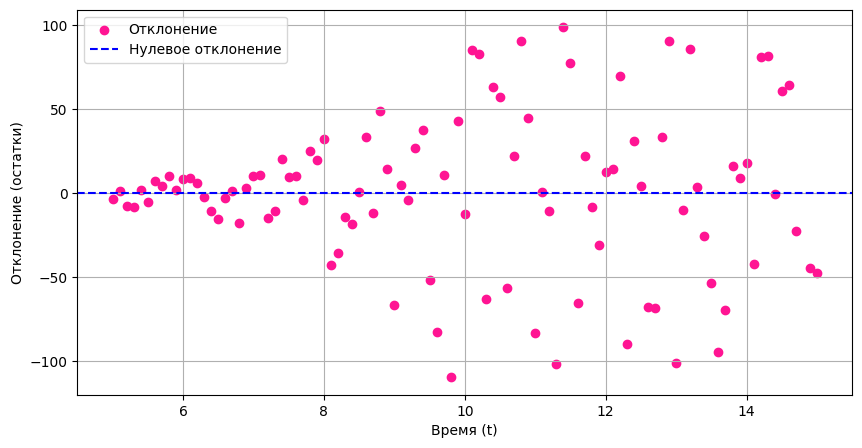

In [310]:
residuals = y - ypred_box

plt.figure(figsize=(10, 5))
plt.scatter(x, residuals, color='deeppink', label='Отклонение')
plt.axhline(y=0, linestyle='--', color='blue', label='Нулевое отклонение')
plt.xlabel('Время (t)')
plt.ylabel('Отклонение (остатки)')
plt.legend()
plt.grid(True)
plt.show()

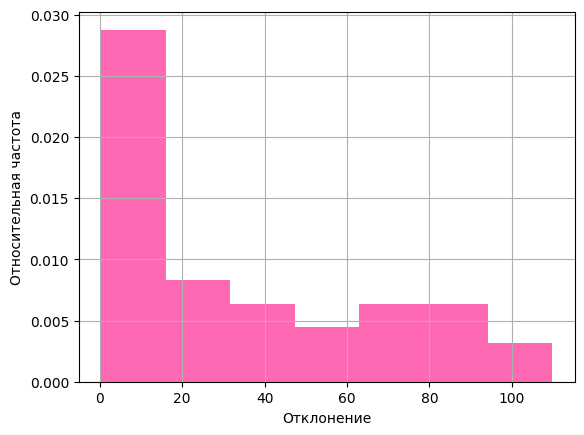

In [311]:
# посмотрим на частоту отклонений
residuals = np.abs(y - ypred_box)

n = y.shape[0]
N = int(1 + 3.2 * np.log10(n))
plt.hist(residuals, N, color='hotpink', density=True)
plt.ylabel('Относительная частота')
plt.xlabel('Отклонение')
plt.grid()
plt.show()

In [312]:
residuals = y - ypred_box
print("MAE:", np.mean(np.abs(residuals)))

MAE: 34.40663434944074


### Есть идея, что можно попробовать подобрать шум так, чтобы уменьшить ошибку. То есть к уже предсказанным данным попробовать эмпирически подобрать шум. Сделаю, если успею.

### Значение MAE улучшилось

In [313]:
print("Популяция на старте, T=0:", g(lsm.x, 0, 0))

Популяция на старте, T=0: 52.17141178238866


# Задание 4

MAE на обучающей выборке: 34.613456292460214 , MSE на обучающей выборке: 2197.6785560997932 , mean: 429.05
MAE на тестовой выборке: 56.97477278358821 , MSE на тестовой выборке: 13658.54682017259 , mean: 414.95238095238096


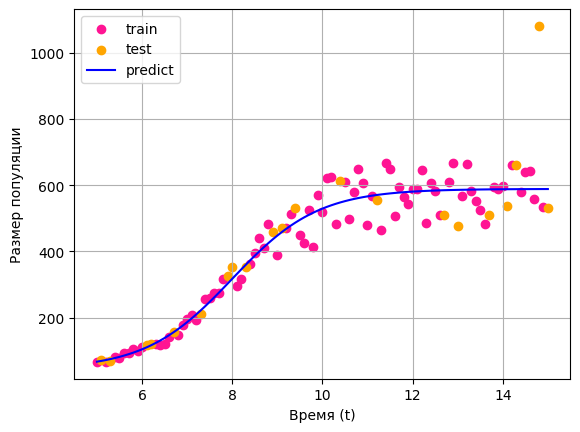

In [314]:
x = df.t
y = df.population
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=8)

def g(x, t, y):
    e = math.e
    a = x[0]
    b = x[1]
    c = x[2]
    d = x[3]
    return c * e**(a * t + b) / (1 + e**(a * t + b)) + d - y

inits = [1, 1, 1, 0]

lsm = least_squares(g, inits, args=(x_train, y_train))

print("MAE на обучающей выборке:", mean_absolute_error(y_train, g(lsm.x,x_train,0)), ", MSE на обучающей выборке:", mean_squared_error(y_train, g(lsm.x,x_train,0)), ", mean:", np.mean(y_train))
print("MAE на тестовой выборке:", mean_absolute_error(y_test, g(lsm.x,x_test,0)), ", MSE на тестовой выборке:", mean_squared_error(y_test, g(lsm.x,x_test,0)), ", mean:", np.mean(y_test))

plt.scatter(x_train, y_train, label='train', color='deeppink')
plt.scatter(x_test, y_test, label='test', color='orange')
plt.plot(x, g(lsm.x, x, 0), label='predict', color='blue')
plt.xlabel('Время (t)')
plt.ylabel('Размер популяции')
plt.legend()
plt.grid(True)
plt.show()


MAE на обучающей выборке: 35.997015545330484 , MSE на обучающей выборке: 2353.4451448414397 , mean: 428.5875
MAE на тестовой выборке: 29.806306345128416 , MSE на тестовой выборке: 1550.6770897602153 , mean: 383.5


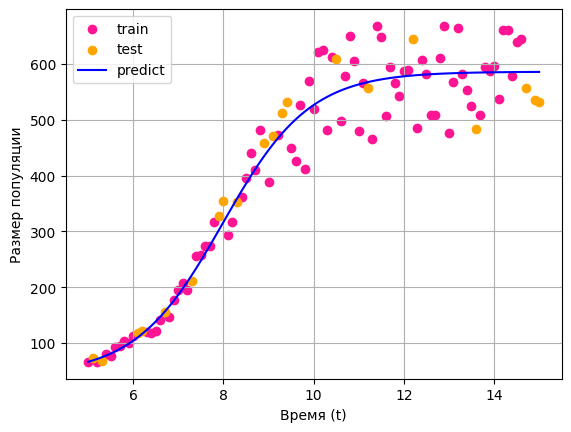

In [315]:
clean_df = df[df.population < np.max(df.population)]
x = clean_df.t
y = clean_df.population
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=8)

def g(x, t, y):
    e = math.e
    a = x[0]
    b = x[1]
    c = x[2]
    d = x[3]
    return c * e**(a * t + b) / (1 + e**(a * t + b)) + d - y

inits = [1, 1, 1, 0]

lsm = least_squares(g, inits, args=(x_train, y_train))

print("MAE на обучающей выборке:", mean_absolute_error(y_train, g(lsm.x,x_train,0)), ", MSE на обучающей выборке:", mean_squared_error(y_train, g(lsm.x,x_train,0)), ", mean:", np.mean(y_train))
print("MAE на тестовой выборке:", mean_absolute_error(y_test, g(lsm.x,x_test,0)), ", MSE на тестовой выборке:", mean_squared_error(y_test, g(lsm.x,x_test,0)), ", mean:", np.mean(y_test))

plt.scatter(x_train, y_train, label='train', color='deeppink')
plt.scatter(x_test, y_test, label='test', color='orange')
plt.plot(x, g(lsm.x, x, 0), label='predict', color='blue')
plt.xlabel('Время (t)')
plt.ylabel('Размер популяции')
plt.legend()
plt.grid(True)
plt.show()


### Убрали сильно отличающееся значение -- и получилось так, что метрики на тесте даже уменьшились, причин считать что модель переобучена вроде бы нет